# MLOps local : expériences reproductibles et surveillance des entrées

**Objectifs.** Définir un protocole train/validation/test, comparer des configurations dans une table d’expériences, conserver la pipeline de preprocessing avec le modèle, puis visualiser une dérive de distribution. Durée : 90–120 min. Tout fonctionne sur CPU avec les dépendances de base.

Ce notebook suit un petit problème d’attrition **synthétique**. Les paramètres du générateur sont connus dans `learning_hub.preprocessing`; les scores ne décrivent aucun client réel. Le [MLOps Zoomcamp](https://github.com/DataTalksClub/mlops-zoomcamp) inspire la progression expériences → artefact → service → monitoring, sans reprise de code ni de texte. L’API et le conteneur sont détaillés dans [`projects/end-to-end-ml`](../../projects/end-to-end-ml/README.md).

## 1. Définir ce qui rend une expérience comparable

Une ligne d’expérience doit contenir au minimum : version du code et des données, split, seed, features, pipeline, hyperparamètres et métrique. Ici les données sont régénérées par `random_state=42`; les transformations apprises restent dans chaque fold de la pipeline.

**Question.** Quelle classe est positive ? Ici `1` signifie « attrition simulée ». Average Precision décrit le classement de cette classe au fil des seuils. L’accuracy d’une classe majoritaire serait trompeuse pour choisir un modèle.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from learning_hub.preprocessing import make_churn_data, make_tabular_preprocessor

SEED = 42
features, target = make_churn_data(n_samples=1_000, random_state=SEED)
x_train, x_test, y_train, y_test = train_test_split(
    features, target, test_size=0.25, stratify=target, random_state=SEED
)
print("train/test:", x_train.shape, x_test.shape)
print("classe positive train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

## 2. Tracer les essais sur le train

La régularisation de `LogisticRegression` dépend de `C` : une petite valeur contraint davantage les coefficients. La validation croisée compare trois valeurs en utilisant le **même** protocole. Le jeu test n’intervient pas dans le choix. La moyenne des folds donne un repère, tandis que leur dispersion montre une partie de l’incertitude due au split.

In [ ]:
numeric = ["tenure_months", "monthly_charge", "support_calls_90d"]
categorical = ["contract"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
records = []
for c_value in [0.05, 0.5, 5.0]:
    candidate = Pipeline([
        ("preprocess", make_tabular_preprocessor(numeric, categorical)),
        ("model", LogisticRegression(C=c_value, max_iter=1_000)),
    ])
    fold_scores = cross_val_score(candidate, x_train, y_train, cv=folds, scoring="average_precision")
    records.append({
        "seed": SEED, "C": c_value, "metric": "average_precision",
        "mean_cv": fold_scores.mean(), "std_cv": fold_scores.std(),
        "fold_scores": fold_scores.tolist(),
    })
experiment_table = pd.DataFrame(records)
experiment_table[["seed", "C", "metric", "mean_cv", "std_cv"]].round(3)

### Visualisation — comparaison des expériences

Les barres montrent la moyenne d’Average Precision ; les moustaches montrent l’écart-type des cinq folds. Une petite différence inférieure à la variabilité des folds mérite prudence. Ce graphique montre les scores de **validation**, pas le test.

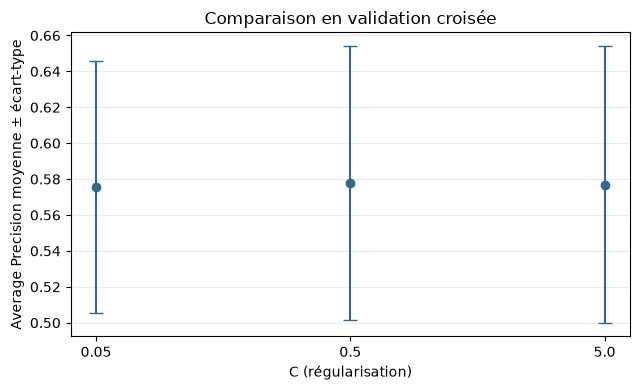

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(
    experiment_table["C"].astype(str), experiment_table["mean_cv"],
    yerr=experiment_table["std_cv"], fmt="o", capsize=5, color="#31688e"
)
ax.set(xlabel="C (régularisation)", ylabel="Average Precision moyenne ± écart-type", title="Comparaison en validation croisée")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Figer le choix et mesurer sur le test

On sélectionne `C` avec la moyenne de validation, puis on réentraîne sur tout le train. Le test est consulté une fois pour le rapport final. Ces métriques sont liées au générateur synthétique, à la taille et au split. Un seuil opérationnel exige un coût des erreurs explicite.

In [ ]:
best_c = float(experiment_table.loc[experiment_table["mean_cv"].idxmax(), "C"])
final_pipeline = Pipeline([
    ("preprocess", make_tabular_preprocessor(numeric, categorical)),
    ("model", LogisticRegression(C=best_c, max_iter=1_000)),
]).fit(x_train, y_train)
probabilities = final_pipeline.predict_proba(x_test)[:, 1]
baseline = DummyClassifier(strategy="prior").fit(x_train, y_train)
baseline_probabilities = baseline.predict_proba(x_test)[:, 1]
print("C retenu:", best_c)
print("baseline AP:", round(average_precision_score(y_test, baseline_probabilities), 3))
print("pipeline AP:", round(average_precision_score(y_test, probabilities), 3))
print("pipeline ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))
print("pipeline F1 au seuil 0.5:", round(f1_score(y_test, probabilities >= 0.5), 3))

## 4. Sérialiser toute la pipeline

Un modèle seul ne sait pas traiter les catégories et échelles brutes. On sérialise l’objet complet. `joblib` peut exécuter du code arbitraire au chargement : ne charger que des artefacts produits par une source de confiance. On utilise un buffer en mémoire pour ne pas committer de poids ou de modèle.

In [ ]:
import io
import joblib

buffer = io.BytesIO()
joblib.dump(final_pipeline, buffer)
buffer.seek(0)
restored_pipeline = joblib.load(buffer)
original = final_pipeline.predict_proba(x_test.iloc[:3])[:, 1]
restored = restored_pipeline.predict_proba(x_test.iloc[:3])[:, 1]
print("Prédictions identiques après rechargement:", np.allclose(original, restored))

## 5. Surveiller une dérive des données

Un service doit vérifier la validité des entrées et observer leur distribution au fil du temps. Nous simulons ici un lot récent dont `monthly_charge` est plus élevé de 20 unités. C’est un décalage **fabriqué**, sans effet sur les vrais labels dans cet exemple. Une alerte de dérive de feature ne prouve pas que le modèle est mauvais ; la performance exige des labels observés plus tard.

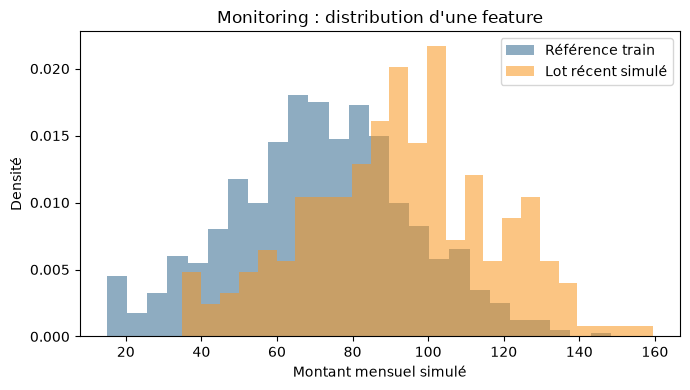

In [ ]:
recent = x_test.copy()
recent["monthly_charge"] = recent["monthly_charge"] + 20
reference_values = x_train["monthly_charge"]
recent_values = recent["monthly_charge"]
standardized_mean_shift = (recent_values.mean() - reference_values.mean()) / reference_values.std()
print("Décalage des moyennes en unités d'écart-type train:", round(standardized_mean_shift, 2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(reference_values, bins=25, density=True, alpha=0.55, label="Référence train", color="#31688e")
ax.hist(recent_values, bins=25, density=True, alpha=0.55, label="Lot récent simulé", color="#f8961e")
ax.set(xlabel="Montant mensuel simulé", ylabel="Densité", title="Monitoring : distribution d'une feature")
ax.legend(); plt.tight_layout(); plt.show()

### Schéma — du modèle validé à la décision

Le chemin du haut distingue l'expérience, l'artefact complet et le service d'inférence. Le suivi sépare les **entrées** (schéma, valeurs manquantes, distributions), le **service** (volume, latence, erreurs) et la **qualité du modèle** (à mesurer lorsque les vrais labels arrivent). Une dérive des entrées ne prouve donc pas une baisse de précision, et une alerte ne commande pas automatiquement un réentraînement : elle ouvre un diagnostic.

Le cycle général s'inspire du [parcours MLOps de GeeksforGeeks](https://www.geeksforgeeks.org/machine-learning/mlops-pipeline-implementing-efficient-machine-learning-operations/) ; le schéma et ses exemples sont originaux. La figure décrit des responsabilités, elle ne signifie pas que ce notebook déploie réellement une API ou collecte des labels en production.

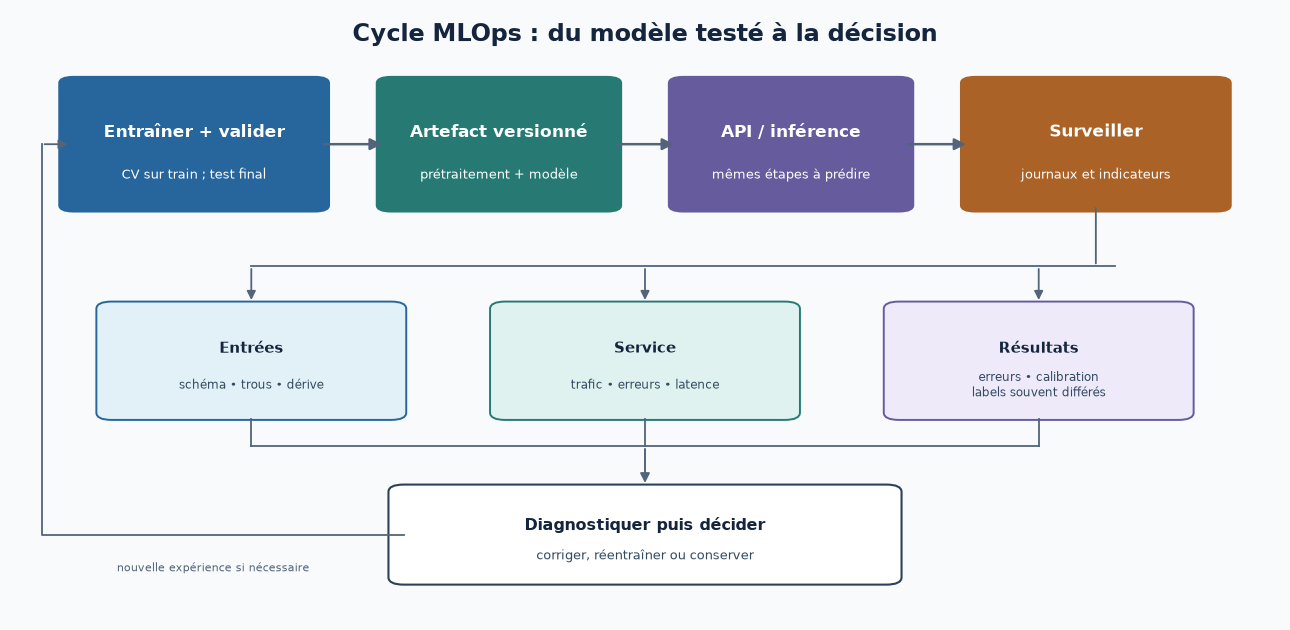

In [ ]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 6.4), facecolor="#f8fafc")
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")
ax.text(0.5, 0.96, "Cycle MLOps : du modèle testé à la décision", ha="center",
        va="center", fontsize=17, fontweight="bold", color="#14253d")

def stage(x, width, color, title, detail):
    box = FancyBboxPatch((x, 0.68), width, 0.20, boxstyle="round,pad=0.012",
                         linewidth=0, facecolor=color)
    ax.add_patch(box)
    ax.text(x + width / 2, 0.80, title, ha="center", va="center",
            fontsize=12, fontweight="bold", color="white")
    ax.text(x + width / 2, 0.73, detail, ha="center", va="center",
            fontsize=9.5, color="white")

stage(0.05, 0.19, "#27669d", "Entraîner + valider", "CV sur train ; test final")
stage(0.30, 0.17, "#267a73", "Artefact versionné", "prétraitement + modèle")
stage(0.53, 0.17, "#665b9c", "API / inférence", "mêmes étapes à prédire")
stage(0.76, 0.19, "#aa6227", "Surveiller", "journaux et indicateurs")

for left, right in [(0.24, 0.30), (0.47, 0.53), (0.70, 0.76)]:
    ax.add_patch(FancyArrowPatch((left + 0.005, 0.78), (right - 0.005, 0.78),
                                 arrowstyle="-|>", mutation_scale=17,
                                 linewidth=1.8, color="#53647a"))

signals = [
    (0.08, "Entrées", "schéma • trous • dérive", "#e2f0f7", "#27669d"),
    (0.39, "Service", "trafic • erreurs • latence", "#e0f2ef", "#267a73"),
    (0.70, "Résultats", "erreurs • calibration\nlabels souvent différés", "#eeeafa", "#665b9c"),
]
for x, title, detail, fill, edge in signals:
    box = FancyBboxPatch((x, 0.34), 0.22, 0.17, boxstyle="round,pad=0.012",
                         linewidth=1.4, edgecolor=edge, facecolor=fill)
    ax.add_patch(box)
    ax.text(x + 0.11, 0.445, title, ha="center", va="center",
            fontsize=11, fontweight="bold", color="#14253d")
    ax.text(x + 0.11, 0.385, detail, ha="center", va="center",
            fontsize=8.8, color="#334b60")

ax.plot([0.19, 0.87], [0.58, 0.58], color="#53647a", linewidth=1.3)
ax.add_patch(FancyArrowPatch((0.855, 0.68), (0.855, 0.58),
                             arrowstyle="-", linewidth=1.3, color="#53647a"))
for x in [0.19, 0.50, 0.81]:
    ax.add_patch(FancyArrowPatch((x, 0.58), (x, 0.52),
                                 arrowstyle="-|>", mutation_scale=13,
                                 linewidth=1.3, color="#53647a"))
    ax.plot([x, x], [0.33, 0.285], color="#53647a", linewidth=1.3)
ax.plot([0.19, 0.81], [0.285, 0.285], color="#53647a", linewidth=1.3)

decision = FancyBboxPatch((0.31, 0.07), 0.38, 0.14, boxstyle="round,pad=0.012",
                          linewidth=1.5, edgecolor="#2d4057", facecolor="#ffffff")
ax.add_patch(decision)
ax.text(0.50, 0.155, "Diagnostiquer puis décider", ha="center", va="center",
        fontsize=11.5, fontweight="bold", color="#14253d")
ax.text(0.50, 0.105, "corriger, réentraîner ou conserver", ha="center",
        va="center", fontsize=9.5, color="#334b60")
ax.add_patch(FancyArrowPatch((0.50, 0.285), (0.50, 0.22),
                             arrowstyle="-|>", mutation_scale=14,
                             linewidth=1.4, color="#53647a"))
ax.plot([0.31, 0.025, 0.025], [0.14, 0.14, 0.78],
        color="#53647a", linewidth=1.3)
ax.add_patch(FancyArrowPatch((0.025, 0.78), (0.048, 0.78),
                             arrowstyle="-|>", mutation_scale=14,
                             linewidth=1.3, color="#53647a"))
ax.text(0.16, 0.085, "nouvelle expérience si nécessaire", ha="center",
        va="center", fontsize=8.2, color="#53647a")
plt.tight_layout()
plt.show()

## 6. Passer du notebook à un système suivi

Le service [FastAPI local](../../projects/end-to-end-ml/README.md) expose le modèle, tandis qu’un suivi réel devrait enregistrer volume de requêtes, taux de valeurs manquantes, catégories inédites, latence et dérive de distributions. Quand les labels arrivent, mesurer precision/recall, calibration et performance par groupe. Chaque alerte doit désigner une personne et une action (inspecter, suspendre, réentraîner, revenir à une version antérieure).

MLflow est optionnel : après `python -m pip install -e ".[mlops]"`, la commande `python projects/end-to-end-ml/train.py --mlflow` journalise paramètres et métriques localement. Les premières cellules de ce notebook restent exécutables sans serveur MLflow.

**À retenir.** Une expérience reproductible inclut plus que la seed. Le test final reste hors du tuning. Un histogramme d’entrée signale une distribution qui change ; il ne mesure ni la qualité du modèle ni la cause de la dérive.

**Exercice.** Modifiez une seule feature du lot récent, tracez sa distribution et définissez un seuil d’alerte provisoire justifié par la variabilité historique. Comparez ensuite deux graines de split et discutez la stabilité du choix de `C`.